# 03 · Expected information gain (EIG) decomposition: joint EIG = Model EIG + Parameter EIG, and how expected predictive information gain (EPIG) differs

Each round, the engine chooses the next experiment by scoring candidate **designs** with a
**design criterion**; the paper compares five of them (the **arms**): joint EIG, Model EIG,
Parameter EIG, EPIG and random designs. This notebook computes the first four with the engine's
own functions, first on a tiny hand-made probability table that can be checked by hand, then
on a saved posterior, and plots them against the design.

- **Needs:** the base install. No run folder: this notebook does not depend on notebook 01.
- **Runtime:** under a minute.

The definitions follow section 10 of [notebook 00](00_how_it_works.ipynb) (in short:
[`FLOW.md`](../FLOW.md#the-five-design-criteria)); terms are in notebook 00's glossary.

## 1. Setup

In [1]:
import json
import logging
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.special import xlogy


def find_repo_root(start):
    for folder in (start, *start.parents):
        if (folder / "pyproject.toml").is_file() and (folder / "src" / "bayes_model_discovery").is_dir():
            return folder
    raise FileNotFoundError("start Jupyter inside the repository checkout")


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
try:
    import bayes_model_discovery  # noqa: F401
except ImportError:  # not installed: use the source tree directly
    sys.path.insert(0, str(REPO / "src"))
logging.getLogger("pytensor.tensor.blas").setLevel(logging.ERROR)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

from bayes_model_discovery.eig.joint import choose_design  # noqa: E402
from bayes_model_discovery.experimental import count_inference, design_policies  # noqa: E402

## 2. The quantities

The pool holds models m with **evidence weights** w_m. Each model is represented by posterior
**particles** θ_{m,1}, …, θ_{m,K}. One particle gives a predictive distribution
p(y | x, m, θ) for the outcome y at design x; averaging over a model's particles gives its
predictive p̄_m(y | x); mixing the models with their weights gives the pool's predictive
p̄(y | x). H is the entropy, in nats. With these:

$$a_{\mathrm{joint}}(x) = H[\bar p(\cdot\mid x)] - \sum_m w_m \tfrac{1}{K}\sum_k H[p(\cdot\mid x, m, \theta_{m,k})]$$

$$a_{\mathrm{model}}(x) = H[\bar p(\cdot\mid x)] - \sum_m w_m\, H[\bar p_m(\cdot\mid x)]$$

$$a_{\mathrm{param}}(x) = \sum_m w_m\, H[\bar p_m(\cdot\mid x)] - \sum_m w_m \tfrac{1}{K}\sum_k H[p(\cdot\mid x, m, \theta_{m,k})]$$

In words: the uncertainty of the pool's prediction, minus the part that would remain even if we
knew the model and its coefficients (the outcome's own noise), is the expected information an
observation at x gives about (model, coefficients): the **joint EIG**. Subtracting instead the
uncertainty that would remain if we knew only the model gives the information about which
model is right, the **Model EIG** (`structure_eig` in the records). The rest is information
about the coefficients within the models, the **Parameter EIG**. The middle term cancels, so
joint EIG = Model EIG + Parameter EIG at every design.

**EPIG** (expected predictive information gain) asks a different question: how much does an
observation at x tell us about outcomes at a fixed set T of target inputs?

$$a_{\mathrm{EPIG}}(x) = \frac{1}{|T|}\sum_{x_*\in T} I(Y_x; Y_{x_*} \mid D)$$

For outcomes that are counts out of a fixed number of trials, the engine computes all of these
as exact sums over every possible outcome; nothing is sampled except the posterior particles.

## 3. A tiny table you can check by hand

Two models, A and B, with equal weights, two particles each, four designs, and an outcome
with two values (success or failure). Each prediction is then one success probability:

In [2]:
labels = ["x1", "x2", "x3", "x4"]
p_A = np.array([[0.50, 0.50], [0.80, 0.80], [0.85, 0.15], [0.05, 0.90]])  # [design, particle]
p_B = np.array([[0.50, 0.50], [0.20, 0.20], [0.15, 0.85], [0.05, 0.05]])
weights = np.array([0.5, 0.5])
display(pd.DataFrame(np.hstack([p_A, p_B]), index=labels,
                     columns=["A, particle 1", "A, particle 2", "B, particle 1", "B, particle 2"]))

,"A, particle 1","A, particle 2","B, particle 1","B, particle 2"
x1,0.50,0.50,0.50,0.50
x2,0.80,0.80,0.20,0.20
x3,0.85,0.15,0.15,0.85
x4,0.05,0.90,0.05,0.05


The engine's exact-sum function is `count_inference.information_from_components`. It takes one
array per model, laid out as [particle, design, outcome], and the model weights, and returns
the three EIG columns. The same numbers by hand, from the definitions above:

In [3]:
def bank(p):
    """Success probabilities [design, particle] as the engine's layout [particle, design, outcome]."""
    return np.stack([1 - p.T, p.T], axis=-1)


def entropy(pmf):
    return -np.sum(xlogy(pmf, pmf), axis=-1)


banks = [bank(p_A), bank(p_B)]
model_predictive = np.stack([b.mean(axis=0) for b in banks])                  # p̄_m, [model, design, outcome]
pool_predictive = np.einsum("m,mxy->xy", weights, model_predictive)            # p̄
h_pool = entropy(pool_predictive)
h_models = weights @ entropy(model_predictive)                                 # Σ w_m H[p̄_m]
h_particles = sum(w * entropy(b).mean(axis=0) for w, b in zip(weights, banks, strict=True))  # Σ w_m mean_k H[p_mk]

joint, model, parameter = count_inference.information_from_components(banks, weights)
toy = pd.DataFrame({"joint EIG": joint, "Model EIG": model, "Parameter EIG": parameter,
                    "joint by hand": h_pool - h_particles, "Model by hand": h_pool - h_models,
                    "Parameter by hand": h_models - h_particles}, index=labels)
display(toy)
by_hand = np.stack([h_pool - h_particles, h_pool - h_models, h_models - h_particles])
print("engine == by hand (to 1e-15):", np.allclose(np.stack([joint, model, parameter]), by_hand, rtol=0, atol=1e-15))
print(f"largest |joint EIG - (Model EIG + Parameter EIG)|: {np.abs(joint - model - parameter).max():.1e}")

rows = [{"design": index + 1, "eig": j, "structure_eig": m, "parameter_eig": p}
        for index, (j, m, p) in enumerate(zip(joint, model, parameter, strict=True))]
for key, name in (("eig", "joint EIG"), ("structure_eig", "Model EIG"), ("parameter_eig", "Parameter EIG")):
    print(f"{name:14} picks x{choose_design(rows, key)['chosen_design']}")

,joint EIG,Model EIG,Parameter EIG,joint by hand,Model by hand,Parameter by hand
x1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
x2,0.1927,0.1927,0.0000,0.1927,0.1927,0.0000
x3,0.2704,0.0000,0.2704,0.2704,0.0000,0.2704
x4,0.3455,0.1304,0.2150,0.3455,0.1304,0.2150


engine == by hand (to 1e-15): True
largest |joint EIG - (Model EIG + Parameter EIG)|: 0.0e+00
joint EIG      picks x4
Model EIG      picks x2
Parameter EIG  picks x3


Each design isolates one case:

- **x1**: every particle of both models predicts 50%. The outcome is a coin flip whatever is
  true, so it teaches nothing: all three are 0.
- **x2**: A predicts 80% and B 20%, each sure of itself. The outcome tells which model is
  right (Model EIG), but nothing about the coefficients within a model (Parameter EIG = 0).
- **x3**: within each model the particles disagree (85% or 15%), but both models average to
  50%. The outcome cannot favor either model (Model EIG = 0) but tells which particles are
  right (Parameter EIG).
- **x4**: A is unsure (5% or 90%) and B is sure (5%). The outcome tells something about both,
  so the sum is largest.

So the three criteria pick three different designs: Model EIG picks x2, Parameter EIG x3 and
joint EIG x4. `eig.joint.choose_design` is the engine's one argmax; ties within 1e-12 go to the
smallest design.

## 4. A saved posterior

`src/bayes_model_discovery/experimental/fixtures/fe0_t18/` holds one fitted model from round 18
of a run on BoxingGym's death-process task, where the outcome is a count out of 50 trials at
one input, a time t in [0.001, 2]. `model.json` has the expression, family, coefficient roles
and log evidence, and `particles.npz` 1,000 posterior particles; the unit test
`test_count_normalization.py` uses the same files. The task's **interface** comes from
`boxinggym_core.TASKS`, which needs no BoxingGym checkout. `tz` is t rescaled to [-1, 1].

In [4]:
from bayes_model_discovery.experimental import boxinggym_core
from bayes_model_discovery.experimental.count_models import Hypothesis

FIXTURE = Path("src/bayes_model_discovery/experimental/fixtures/fe0_t18")
saved_model = json.loads((FIXTURE / "model.json").read_text())
interface = boxinggym_core.TASKS["death"].interface()
input_names = tuple(item["name"] for item in interface["inputs"]) + tuple(interface["derived_inputs"])
roles = tuple(saved_model["parameters"].items())
with np.load(FIXTURE / "particles.npz") as saved:
    particles = {name: saved[name] for name in saved.files}
model_a = count_inference.Fit(Hypothesis(saved_model["expression"], saved_model["family"], roles, input_names),
                              particles, saved_model["log_evidence"])
low, high = interface["inputs"][0]["range"]
designs = np.linspace(low, high, 41)
print(f"model A: {saved_model['expression']} | {saved_model['family']}")
print(f"         roles {saved_model['parameters']}, log evidence {saved_model['log_evidence']:.2f}")
print(f"         {len(particles['b0'])} particles of {', '.join(particles)}")
print(f"interface: input t in [{low}, {high}], derived {interface['derived_inputs']}, {interface['trials']} trials")
print(f"design grid: {len(designs)} designs from {designs[0]} to {designs[-1]}")

model A: b0+b1*tz+b2*square(tz)+b3*tanh(tz)+b4*power(tz,3)+b5*log(1+t) | beta_binomial
         roles {'b0': 'intercept', 'b1': 'signed', 'b2': 'signed', 'b3': 'signed', 'b4': 'signed', 'b5': 'positive'}, log evidence -59.22
         1000 particles of b0, b1, b2, b3, b4, b5, rho
interface: input t in [0.001, 2.0], derived {'t01': '(t-0.001)/1.999', 'tz': '2*(t-0.001)/(2.0-0.001)-1'}, 50 trials
design grid: 41 designs from 0.001 to 2.0


**One model in the pool.** `count_inference.choose` is the function the synthetic count runner
uses for this step (through `design_policies.select`). It draws `posterior_samples` particles
per model (128, as in the paper profile) with a fixed seed, uses the same draws at every
design, and returns one row per design with the three columns. With a single model there is
nothing to learn about which model is right: Model EIG is exactly zero at every design, and
joint EIG equals Parameter EIG. Every design then ties for Model EIG, and the tie rule picks
the smallest one, so a Model EIG arm has nothing to work with.

In [5]:
SEED, SAMPLES = 0, 128
chosen, rows_a = count_inference.choose([model_a], designs, SEED, SAMPLES, interface, interface["trials"])
one_model = pd.DataFrame(rows_a)
print("largest Model EIG:", one_model["structure_eig"].abs().max())
print("joint EIG == Parameter EIG at every design:", bool((one_model["eig"] == one_model["parameter_eig"]).all()))
for key, name in (("eig", "joint EIG"), ("structure_eig", "Model EIG"), ("parameter_eig", "Parameter EIG")):
    decision = choose_design(rows_a, key)
    tied = decision["n_tied_at_max"]
    print(f"{name:14} picks t = {decision['chosen_design']:.4f} (value {decision['top_value']:.4f}; "
          f"{tied} design{'s' if tied > 1 else ''} at the maximum)")

largest Model EIG: 0.0
joint EIG == Parameter EIG at every design: True
joint EIG      picks t = 2.0000 (value 0.2174; 1 design at the maximum)
Model EIG      picks t = 0.0010 (value 0.0000; 41 designs at the maximum)
Parameter EIG  picks t = 2.0000 (value 0.2174; 1 design at the maximum)


**Two models.** To give Model EIG something to separate, we add a rival model C by hand: the
same expression without the cubic term `b4*power(tz,3)`, using the other coefficients of the
same particles. Model C is not a fitted posterior; it only stands for a rival structure that
differs from A in one term, as candidates in a real pool often do. The two get equal weights.
The term `b4*tz**3` vanishes at the center of the range (t ≈ 1) and is largest at both ends, so
that is where an observation can tell A from C.

In [6]:
expression_c = "b0+b1*tz+b2*square(tz)+b3*tanh(tz)+b5*log(1+t)"
model_c = count_inference.Fit(
    Hypothesis(expression_c, saved_model["family"], tuple(r for r in roles if r[0] != "b4"), input_names),
    {name: values for name, values in particles.items() if name != "b4"},
    saved_model["log_evidence"])  # same log evidence: equal weights, chosen by hand
pool = [model_a, model_c]
print("weights:", np.exp(count_inference.model_logweights(pool)))
chosen, rows = count_inference.choose(pool, designs, SEED, SAMPLES, interface, interface["trials"])
criteria = pd.DataFrame(rows).rename(columns={"eig": "joint_eig", "structure_eig": "model_eig"})
gap = (criteria["joint_eig"] - criteria["model_eig"] - criteria["parameter_eig"]).abs().max()
print(f"largest |joint EIG - (Model EIG + Parameter EIG)| over {len(criteria)} designs: {gap:.1e}")
display(criteria.iloc[::5])

weights: [0.5 0.5]
largest |joint EIG - (Model EIG + Parameter EIG)| over 41 designs: 0.0e+00


,design,joint_eig,model_eig,parameter_eig
0,0.0010,0.2844,0.1205,0.1639
5,0.2509,0.2045,0.0646,0.1399
10,0.5008,0.1275,0.0141,0.1133
15,0.7506,0.0933,0.0019,0.0914
20,1.0005,0.0806,0.0008,0.0798
25,1.2504,0.0914,0.0002,0.0913
30,1.5003,0.1265,0.0076,0.1188
35,1.7501,0.2525,0.0768,0.1757
40,2.0000,0.5644,0.2400,0.3244


## 5. EPIG on the same grid

`count_inference.choose_epig` computes EPIG for the same designs from the same particle draws.
A run draws its 32 target inputs once at the start (in the synthetic count benchmark uniformly
over the input range) and saves them in `config.json` (`epig_targets`); here they are drawn
uniformly over the death task's input range with a fixed seed. The second
set of targets, all inside [0.5, 1.0], shows what EPIG is for: it values an observation by
what it says about the predictions you care about. `choose_epig` also returns the joint EIG of
each design from the same draws, which matches `choose` to rounding.

In [7]:
targets_full = np.random.default_rng(1).uniform(low, high, count_inference.EPIG_TARGET_POINTS)
targets_middle = np.random.default_rng(1).uniform(0.5, 1.0, count_inference.EPIG_TARGET_POINTS)
epig = {}
for name, targets in (("targets over [0.001, 2]", targets_full), ("targets in [0.5, 1]", targets_middle)):
    chosen_epig, epig_rows = count_inference.choose_epig(pool, designs, SEED, SAMPLES, interface,
                                                         interface["trials"], target_points=targets)
    epig[name] = np.array([row["epig"] for row in epig_rows])
    joint_gap = max(abs(a["joint_eig"] - b["eig"]) for a, b in zip(epig_rows, rows, strict=True))
    print(f"EPIG, {name:24} picks t = {chosen_epig:.4f};  joint EIG columns agree to {joint_gap:.0e}")

EPIG, targets over [0.001, 2]  picks t = 2.0000;  joint EIG columns agree to 3e-15
EPIG, targets in [0.5, 1]      picks t = 0.5507;  joint EIG columns agree to 3e-15


Which design each criterion picks. `design_policies.select` is the engine's selection step for
the joint EIG, Model EIG (`structure_eig`) and EPIG arms. It has no Parameter EIG arm for this
runner (the ChemBench and NeuronBench runners have one), so that column's argmax is taken with
`eig.joint.choose_design`, the same argmax `select` uses.

In [8]:
picks = {}
for policy, name in (("joint_eig", "joint EIG"), ("structure_eig", "Model EIG")):
    picks[name] = design_policies.select(pool, designs, SEED, policy, SAMPLES, interface, interface["trials"])[0]
picks["Parameter EIG"] = choose_design(rows, "parameter_eig")["chosen_design"]
for name, targets in (("EPIG, targets over [0.001, 2]", targets_full), ("EPIG, targets in [0.5, 1]", targets_middle)):
    picks[name] = design_policies.select(pool, designs, SEED, "epig", SAMPLES, interface, interface["trials"],
                                         target_points=targets)[0]
for name, design in picks.items():
    print(f"{name:30} t = {design:.4f}")

joint EIG                      t = 2.0000
Model EIG                      t = 2.0000
Parameter EIG                  t = 2.0000
EPIG, targets over [0.001, 2]  t = 2.0000
EPIG, targets in [0.5, 1]      t = 0.5507


## 6. The four criteria against the design

One panel per criterion, each on its own scale (the values differ by an order of magnitude).
The dot marks the design the criterion picks.

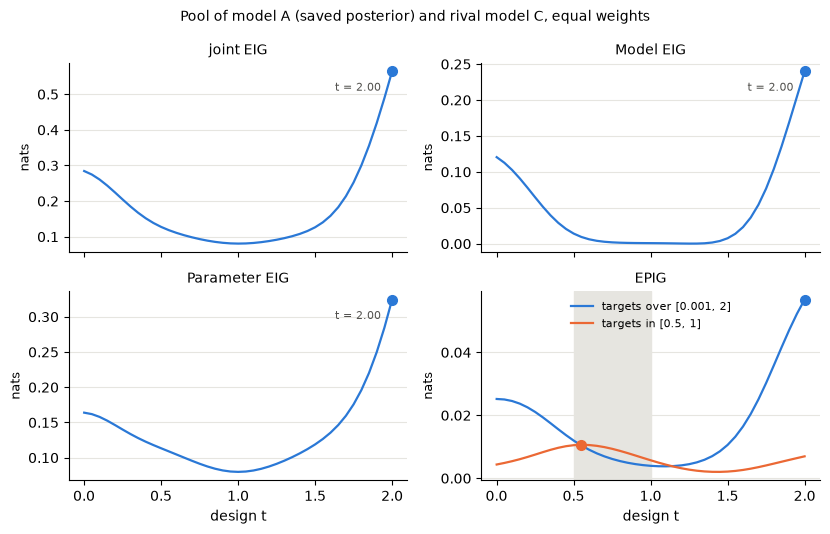

In [9]:
import matplotlib.pyplot as plt

BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#52514e", "#e6e5e0"
panels = [("joint EIG", criteria["joint_eig"].to_numpy()),
          ("Model EIG", criteria["model_eig"].to_numpy()),
          ("Parameter EIG", criteria["parameter_eig"].to_numpy())]
fig, axes = plt.subplots(2, 2, figsize=(8.4, 5.4), dpi=100, sharex=True)
for ax, (name, values) in zip(axes.flat[:3], panels, strict=True):
    best = int(np.argmax(values))
    ax.plot(designs, values, color=BLUE, linewidth=1.6)
    ax.plot(designs[best], values[best], "o", color=BLUE, markersize=7)
    ax.annotate(f"t = {designs[best]:.2f}", (designs[best], values[best]), textcoords="offset points",
                xytext=(-8, -14), ha="right", fontsize=8, color=INK)
    ax.set_title(name, fontsize=10)
ax = axes.flat[3]
ax.axvspan(0.5, 1.0, color=GRID, zorder=0)
for (name, values), color in zip(epig.items(), (BLUE, ORANGE), strict=True):
    best = int(np.argmax(values))
    ax.plot(designs, values, color=color, linewidth=1.6, label=name)
    ax.plot(designs[best], values[best], "o", color=color, markersize=7)
ax.set_title("EPIG", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center")
for ax in axes.flat:
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_ylabel("nats", fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("design t")
fig.suptitle("Pool of model A (saved posterior) and rival model C, equal weights", fontsize=10)
fig.tight_layout()
plt.show()

## 7. Why the criteria can pick different designs

- **Joint EIG** counts every kind of uncertainty an observation can remove, about the model and
  about its coefficients. It is large wherever the pool's prediction is uncertain beyond the
  outcome's own noise.
- **Model EIG** counts only the disagreement between the models' averaged predictions. It is
  zero where the models agree, however unsure each model is about its own coefficients: here,
  near t ≈ 1, where the term that separates A from C vanishes. It is also zero everywhere when
  the pool holds one model.
- **Parameter EIG** counts the disagreement between the particles within each model, averaged
  over models. It is large where the coefficients are poorly constrained, typically where the
  data are sparse or an expression extrapolates.
- **EPIG** counts only information about outcomes at the target inputs. An observation can
  remove a lot of uncertainty about a coefficient that hardly affects the targets; EPIG gives it
  little credit. With targets in [0.5, 1] it picks a design inside that region, while the EIG
  criteria go to the end of the range.

On this saved posterior the three EIG criteria agree: at the upper end of the range the models
disagree most and the coefficients are least constrained, so all three pick t = 2. They agree
only because both kinds of uncertainty peak in the same place; the table of section 3 shows
designs where they do not, and the choice of targets moves EPIG elsewhere. Which criterion
works best for discovering the true law is the question the paper's arms answer empirically
([`FLOW.md`](../FLOW.md#the-protocol-of-the-paper-runs)).

A note on the functions: for counts out of a fixed number of trials, the engine computes the
criteria by exact sums (`count_inference.information_from_components`, called by
`count_inference.choose`, and `count_inference.choose_epig`). Positive, real-valued and vector
outcomes use Monte Carlo estimates instead (`positive_inference.joint_eig`,
`vector_inference.joint_eig`, and `design_policies.structure_eig_from_draws` for the Model EIG
part); this notebook does not need them.